In [ ]:
import tensorflow as tf
print(tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import zipfile, os

# Change this to wherever you put it in Drive
ZIP_PATH = "/content/drive/MyDrive/new_plantset.zip"
EXTRACT  = "/content/plantvillage"

print("Extracting...")
with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    z.extractall(EXTRACT)
print("Done")

# See what structure came out
for root, dirs, files in os.walk(EXTRACT):
    level = root.replace(EXTRACT, '').count(os.sep)
    if level < 3:
        print('  ' * level + os.path.basename(root) + '/')

Extracting...
Done
plantvillage/
  new plant diseases dataset(augmented)/
    New Plant Diseases Dataset(Augmented)/
  test/
    test/
  New Plant Diseases Dataset(Augmented)/
    New Plant Diseases Dataset(Augmented)/


In [ ]:
from pathlib import Path

base = Path(EXTRACT)

train_dir = None
val_dir   = None

for p in base.rglob("*"):
    if p.is_dir() and p.name == "train":
        train_dir = p
    if p.is_dir() and p.name in ("valid", "val", "validation"):
        val_dir = p

print("Train folder :", train_dir)
print("Val folder   :", val_dir)
print("Train classes:", len(list(train_dir.iterdir())))
print("Val classes  :", len(list(val_dir.iterdir())))
print("\nClass names:")
for c in sorted(train_dir.iterdir()):
    if c.is_dir():
        n = len(list(c.glob("*")))
        print(f"  {c.name}: {n} images")

Train folder : /content/plantvillage/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)/train
Val folder   : /content/plantvillage/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)/valid
Train classes: 38
Val classes  : 38

Class names:
  Apple___Apple_scab: 2016 images
  Apple___Black_rot: 1987 images
  Apple___Cedar_apple_rust: 1760 images
  Apple___healthy: 2008 images
  Blueberry___healthy: 1816 images
  Cherry_(including_sour)___Powdery_mildew: 1683 images
  Cherry_(including_sour)___healthy: 1826 images
  Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 1642 images
  Corn_(maize)___Common_rust_: 1907 images
  Corn_(maize)___Northern_Leaf_Blight: 1908 images
  Corn_(maize)___healthy: 1859 images
  Grape___Black_rot: 1888 images
  Grape___Esca_(Black_Measles): 1920 images
  Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 1722 images
  Grape___healthy: 1692 images
  Orange___Haunglongbing_(Citrus_greening): 2010 images
  Peach___Bact

In [ ]:
import shutil, hashlib, random
from pathlib import Path

random.seed(42)

OUT       = Path("/content/data")
EXT       = {".jpg", ".jpeg", ".png"}
CAP_TRAIN = 800
CAP_VAL   = 200

seen = set()

def copy_class(src_dir, dest_dir, cap):
    imgs = [p for p in src_dir.rglob("*")
            if p.suffix.lower() in EXT]
    random.shuffle(imgs)
    dest_dir.mkdir(parents=True, exist_ok=True)
    saved = 0
    for p in imgs:
        if saved >= cap:
            break
        h = hashlib.md5(p.read_bytes()).hexdigest()
        if h in seen:
            continue
        seen.add(h)
        shutil.copy(p, dest_dir / f"{h[:10]}{p.suffix.lower()}")
        saved += 1
    return saved

print("Copying train classes...")
total_train = 0
for cls in sorted(c for c in train_dir.iterdir() if c.is_dir()):
    n = copy_class(cls, OUT / "train" / cls.name, CAP_TRAIN)
    total_train += n
    print(f"  {cls.name}: {n}")

print("\nCopying val classes...")
total_val = 0
for cls in sorted(c for c in val_dir.iterdir() if c.is_dir()):
    n = copy_class(cls, OUT / "val" / cls.name, CAP_VAL)
    total_val += n
    print(f"  {cls.name}: {n}")

classes = [d.name for d in sorted((OUT/"train").iterdir())
           if d.is_dir()]
print(f"\nTotal classes     : {len(classes)}")
print(f"Total train images: {total_train}")
print(f"Total val images  : {total_val}")

Copying train classes...
  Apple___Apple_scab: 800
  Apple___Black_rot: 800
  Apple___Cedar_apple_rust: 800
  Apple___healthy: 800
  Blueberry___healthy: 800
  Cherry_(including_sour)___Powdery_mildew: 800
  Cherry_(including_sour)___healthy: 800
  Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 800
  Corn_(maize)___Common_rust_: 800
  Corn_(maize)___Northern_Leaf_Blight: 800
  Corn_(maize)___healthy: 800
  Grape___Black_rot: 800
  Grape___Esca_(Black_Measles): 800
  Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 800
  Grape___healthy: 800
  Orange___Haunglongbing_(Citrus_greening): 800
  Peach___Bacterial_spot: 800
  Peach___healthy: 800
  Pepper,_bell___Bacterial_spot: 800
  Pepper,_bell___healthy: 800
  Potato___Early_blight: 800
  Potato___Late_blight: 800
  Potato___healthy: 800
  Raspberry___healthy: 800
  Soybean___healthy: 800
  Squash___Powdery_mildew: 800
  Strawberry___Leaf_scorch: 800
  Strawberry___healthy: 800
  Tomato___Bacterial_spot: 800
  Tomato___Early_blight: 800
 

In [ ]:
import json
import numpy as np
import tensorflow as tf
from pathlib import Path

# ── Settings ──────────────────────────────────────────────────────────
DATA          = Path("/content/data")
MODELS        = Path("/content/models")
MODELS.mkdir(exist_ok=True)
IMG           = (224, 224)
BATCH         = 32
SEED          = 42
EPOCHS_PHASE1 = 15
EPOCHS_PHASE2 = 15
PATIENCE      = 6

# ── Load dataset ───────────────────────────────────────────────────────
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA / "train", image_size=IMG,
    batch_size=BATCH, seed=SEED)
val_ds   = tf.keras.utils.image_dataset_from_directory(
    DATA / "val",   image_size=IMG,
    batch_size=BATCH, shuffle=False)

class_names = train_ds.class_names
num_classes = len(class_names)
print(f"Classes: {num_classes}")

json.dump(class_names,
          open(MODELS / "class_names.json", "w"), indent=2)

# ── GPU performance ────────────────────────────────────────────────────
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(AUTOTUNE)
val_ds   = val_ds.cache().prefetch(AUTOTUNE)

# ── Class weights ──────────────────────────────────────────────────────
counts = np.array([
    len(list((DATA / "train" / c).glob("*")))
    for c in class_names], dtype="float")
weights = {i: counts.sum() / (num_classes * n)
           for i, n in enumerate(counts)}

# ── Augmentation ───────────────────────────────────────────────────────
augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.2),
    tf.keras.layers.RandomTranslation(0.1, 0.1),
    tf.keras.layers.RandomBrightness(0.3),
    tf.keras.layers.RandomContrast(0.3),
], name="augmentation")

# ── Model ──────────────────────────────────────────────────────────────
base = tf.keras.applications.MobileNetV2(
    input_shape=IMG + (3,),
    include_top=False,
    weights="imagenet")
base.trainable = False

inputs  = tf.keras.Input(shape=IMG + (3,))
x       = augment(inputs)
x       = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x       = base(x, training=False)
x       = tf.keras.layers.GlobalAveragePooling2D()(x)
x       = tf.keras.layers.BatchNormalization()(x)
x       = tf.keras.layers.Dropout(0.4)(x)
x       = tf.keras.layers.Dense(
              256, activation="relu",
              kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
x       = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(
              num_classes, activation="softmax")(x)
model   = tf.keras.Model(inputs, outputs)

# ── Callbacks ──────────────────────────────────────────────────────────
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        str(MODELS / "best_model.keras"),
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=PATIENCE,
        restore_best_weights=True,
        verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        verbose=1)
]

# ── Phase 1: train head only (base frozen) ─────────────────────────────
print("\n── Phase 1: training head ──")
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])
history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_PHASE1,
    class_weight=weights,
    callbacks=callbacks)

print(f"\nBest val_accuracy phase 1: "
      f"{max(history1.history['val_accuracy'])*100:.2f}%")

# ── Phase 2: fine-tune top 30 layers ───────────────────────────────────
print("\n── Phase 2: fine-tuning top 30 layers ──")
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])
history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_PHASE2,
    class_weight=weights,
    callbacks=callbacks)

print(f"\nBest val_accuracy phase 2: "
      f"{max(history2.history['val_accuracy'])*100:.2f}%")

model.save(MODELS / "final_model.keras")
print("\nTraining complete.")

FileNotFoundError: [Errno 2] No such file or directory: '/content/data/train'

In [ ]:
# Clear everything and start fresh
import gc, shutil, tensorflow as tf
from pathlib import Path

# Delete original extracted folder — you don't need it anymore
# data/train and data/val are already copied
if Path("/content/plantvillage").exists():
    shutil.rmtree("/content/plantvillage")
    print("Deleted /content/plantvillage")

# Clear RAM
try:
    del model, train_ds, val_ds, base
except:
    pass

gc.collect()
tf.keras.backend.clear_session()

# Check RAM now
import psutil
ram = psutil.virtual_memory()
print(f"RAM used : {ram.used / 1e9:.1f} GB")
print(f"RAM free : {ram.available / 1e9:.1f} GB")

Deleted /content/plantvillage
RAM used : 1.5 GB
RAM free : 11.8 GB


In [ ]:
import json, gc
import numpy as np
import tensorflow as tf
from pathlib import Path

# ── Settings ───────────────────────────────────────────────────────────
DATA          = Path("/content/data")
MODELS        = Path("/content/models")
MODELS.mkdir(exist_ok=True)
IMG           = (224, 224)
BATCH         = 8          # reduced from 16
SEED          = 42
EPOCHS_PHASE1 = 15
EPOCHS_PHASE2 = 15
PATIENCE      = 6

# ── GPU memory growth (stops GPU grabbing all RAM at once) ─────────────
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("GPU memory growth enabled")
    except RuntimeError as e:
        print(e)

# ── Load dataset ───────────────────────────────────────────────────────
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA / "train", image_size=IMG,
    batch_size=BATCH, seed=SEED)
val_ds   = tf.keras.utils.image_dataset_from_directory(
    DATA / "val",   image_size=IMG,
    batch_size=BATCH, shuffle=False)

class_names = train_ds.class_names
num_classes = len(class_names)
print(f"Classes: {num_classes}")

json.dump(class_names,
          open(MODELS / "class_names.json", "w"), indent=2)

# ── Prefetch only, no cache ────────────────────────────────────────────
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds   = val_ds.prefetch(AUTOTUNE)

# ── Class weights ──────────────────────────────────────────────────────
counts = np.array([
    len(list((DATA / "train" / c).glob("*")))
    for c in class_names], dtype="float")
weights = {i: counts.sum() / (num_classes * n)
           for i, n in enumerate(counts)}

# ── Augmentation ───────────────────────────────────────────────────────
augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.2),
    tf.keras.layers.RandomBrightness(0.2),
    tf.keras.layers.RandomContrast(0.2),
], name="augmentation")

# ── Model ──────────────────────────────────────────────────────────────
base = tf.keras.applications.MobileNetV2(
    input_shape=IMG + (3,),
    include_top=False,
    weights="imagenet")
base.trainable = False

inputs  = tf.keras.Input(shape=IMG + (3,))
x       = augment(inputs)
x       = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x       = base(x, training=False)
x       = tf.keras.layers.GlobalAveragePooling2D()(x)
x       = tf.keras.layers.BatchNormalization()(x)
x       = tf.keras.layers.Dropout(0.4)(x)
x       = tf.keras.layers.Dense(
              256, activation="relu",
              kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
x       = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(
              num_classes, activation="softmax")(x)
model   = tf.keras.Model(inputs, outputs)

# ── Callbacks ──────────────────────────────────────────────────────────
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        str(MODELS / "best_model.keras"),
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=PATIENCE,
        restore_best_weights=True,
        verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        verbose=1)
]

# ── Phase 1 ────────────────────────────────────────────────────────────
print("\n── Phase 1: training head ──")
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])
history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_PHASE1,
    class_weight=weights,
    callbacks=callbacks)

print(f"\nBest val_accuracy phase 1: "
      f"{max(history1.history['val_accuracy'])*100:.2f}%")

# Clear memory between phases
gc.collect()
tf.keras.backend.clear_session()

# Rebuild model for phase 2 from saved checkpoint
print("\nReloading best model for phase 2...")
model = tf.keras.models.load_model(MODELS / "best_model.keras")

# Get the base layer again for unfreezing
base_layer = model.layers[4]    # MobileNetV2 is always layer 4 in this architecture
base_layer.trainable = True
for layer in base_layer.layers[:-30]:
    layer.trainable = False

# ── Phase 2 ────────────────────────────────────────────────────────────
print("\n── Phase 2: fine-tuning top 30 layers ──")
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])
history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_PHASE2,
    class_weight=weights,
    callbacks=callbacks)

print(f"\nBest val_accuracy phase 2: "
      f"{max(history2.history['val_accuracy'])*100:.2f}%")

model.save(MODELS / "final_model.keras")
print("\nTraining complete.")

GPU memory growth enabled
Found 30400 files belonging to 38 classes.
Found 7600 files belonging to 38 classes.
Classes: 38

── Phase 1: training head ──
Epoch 1/15
3798/3800 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.6082 - loss: 2.0126
Epoch 1: val_accuracy improved from None to 0.86553, saving model to /content/models/best_model.keras

Epoch 1: finished saving model to /content/models/best_model.keras
3800/3800 ━━━━━━━━━━━━━━━━━━━━ 123s 29ms/step - accuracy: 0.6963 - loss: 1.6746 - val_accuracy: 0.8655 - val_loss: 1.0763 - learning_rate: 0.0010
Epoch 2/15
3799/3800 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.7533 - loss: 1.4937
Epoch 2: val_accuracy improved from 0.86553 to 0.88171, saving model to /content/models/best_model.keras

Epoch 2: finished saving model to /content/models/best_model.keras
3800/3800 ━━━━━━━━━━━━━━━━━━━━ 112s 30ms/step - accuracy: 0.7588 - loss: 1.4906 - val_accuracy: 0.8817 - val_loss: 1.0697 - learning_rate: 0.0010
Epoch 3/15
3800/3800 ━━━━━━━━━━━━━

AttributeError: 'BatchNormalization' object has no attribute 'layers'

In [ ]:
import gc
import tensorflow as tf
from pathlib import Path

MODELS = Path("/content/models")

# Clear memory
gc.collect()
tf.keras.backend.clear_session()

# Reload best model from phase 1
print("Reloading best model...")
model = tf.keras.models.load_model(MODELS / "best_model.keras")

# Print all layers to find the MobileNetV2 layer by name
print("\nModel layers:")
for i, layer in enumerate(model.layers):
    print(f"  [{i}] {layer.name:40} {type(layer).__name__}")

Reloading best model...


ValueError: File not found: filepath=/content/models/best_model.keras. Please ensure the file is an accessible `.keras` zip file.

In [ ]:
# Find MobileNetV2 base by name (works regardless of index)
base_layer = None
for layer in model.layers:
    if "mobilenetv2" in layer.name.lower():
        base_layer = layer
        break

if base_layer is None:
    print("ERROR: Could not find MobileNetV2 layer")
    print("Layer names:", [l.name for l in model.layers])
else:
    print(f"Found base layer: {base_layer.name}")
    print(f"Base layer type : {type(base_layer).__name__}")
    print(f"Total layers in base: {len(base_layer.layers)}")

    # Unfreeze top 30 layers
    base_layer.trainable = True
    for layer in base_layer.layers[:-30]:
        layer.trainable = False

    trainable = sum(1 for l in base_layer.layers if l.trainable)
    print(f"Trainable layers in base: {trainable}")

Found base layer: mobilenetv2_1.00_224
Base layer type : Functional
Total layers in base: 154
Trainable layers in base: 30


In [ ]:
# Reload datasets (needed after clear_session)
DATA     = Path("/content/data")
AUTOTUNE = tf.data.AUTOTUNE
IMG      = (224, 224)
BATCH    = 8

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA / "train", image_size=IMG,
    batch_size=BATCH, seed=42)
val_ds   = tf.keras.utils.image_dataset_from_directory(
    DATA / "val",   image_size=IMG,
    batch_size=BATCH, shuffle=False)

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds   = val_ds.prefetch(AUTOTUNE)

import numpy as np
import json

class_names = json.load(open(MODELS / "class_names.json"))
num_classes = len(class_names)
counts = np.array([
    len(list((DATA / "train" / c).glob("*")))
    for c in class_names], dtype="float")
weights = {i: counts.sum() / (num_classes * n)
           for i, n in enumerate(counts)}

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        str(MODELS / "best_model_phase2.keras"),
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=6,
        restore_best_weights=True,
        verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        verbose=1)
]

print("\n── Phase 2: fine-tuning top 30 layers ──")
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])
history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=weights,
    callbacks=callbacks)

best2 = max(history2.history['val_accuracy']) * 100
print(f"\nBest val_accuracy phase 2: {best2:.2f}%")
print(f"Phase 1 was             : 88.17%")
print(f"Improvement             : +{best2 - 88.17:.2f}%")

model.save(MODELS / "final_model.keras")
print("\nDone. Save to Drive now.")

Found 30400 files belonging to 38 classes.
Found 7600 files belonging to 38 classes.

── Phase 2: fine-tuning top 30 layers ──
Epoch 1/15
3799/3800 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.6892 - loss: 1.7346
Epoch 1: val_accuracy improved from None to 0.90026, saving model to /content/models/best_model_phase2.keras

Epoch 1: finished saving model to /content/models/best_model_phase2.keras
3800/3800 ━━━━━━━━━━━━━━━━━━━━ 165s 41ms/step - accuracy: 0.7360 - loss: 1.5729 - val_accuracy: 0.9003 - val_loss: 1.0054 - learning_rate: 1.0000e-05
Epoch 2/15
3799/3800 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.7935 - loss: 1.3701
Epoch 2: val_accuracy improved from 0.90026 to 0.91421, saving model to /content/models/best_model_phase2.keras

Epoch 2: finished saving model to /content/models/best_model_phase2.keras
3800/3800 ━━━━━━━━━━━━━━━━━━━━ 150s 39ms/step - accuracy: 0.8037 - loss: 1.3211 - val_accuracy: 0.9142 - val_loss: 0.9510 - learning_rate: 1.0000e-05
Epoch 3/15
3799/3800 ━━━

In [ ]:
import shutil
from pathlib import Path

dest = Path("/content/drive/MyDrive/agrovision_model")
dest.mkdir(exist_ok=True)

# Save whichever is better — phase2 if it improved, phase1 if not
import json
h2_best = max(history2.history['val_accuracy']) * 100

if h2_best > 88.17:
    best_file = "best_model_phase2.keras"
    print(f"Phase 2 won: {h2_best:.2f}%")
else:
    best_file = "best_model.keras"
    print(f"Phase 1 was better: 88.17%")

shutil.copy(f"/content/models/{best_file}",
            dest / "best_model.keras")
shutil.copy("/content/models/class_names.json",
            dest / "class_names.json")

print(f"Saved to Drive: {dest}")

Phase 2 won: 96.07%
Saved to Drive: /content/drive/MyDrive/agrovision_model


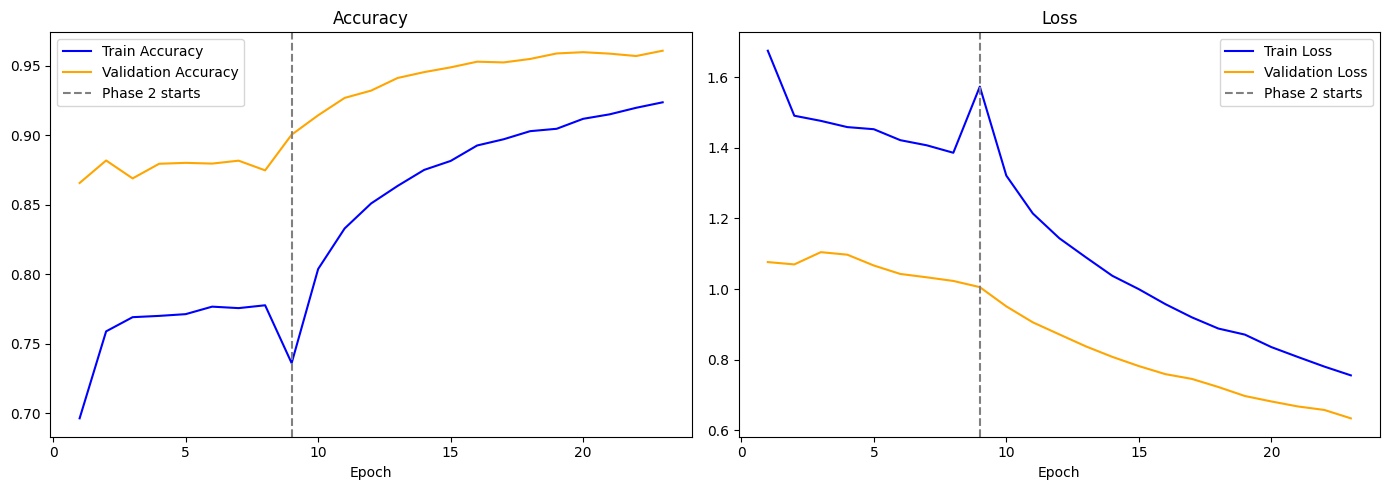

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

acc      = history1.history['accuracy']     + history2.history['accuracy']
val_acc  = history1.history['val_accuracy'] + history2.history['val_accuracy']
loss     = history1.history['loss']         + history2.history['loss']
val_loss = history1.history['val_loss']     + history2.history['val_loss']

epochs_range = range(1, len(acc) + 1)
phase2_start = len(history1.history['accuracy']) + 1

axes[0].plot(epochs_range, acc,     label="Train Accuracy",      color="blue")
axes[0].plot(epochs_range, val_acc, label="Validation Accuracy", color="orange")
axes[0].axvline(x=phase2_start, color="gray",
                linestyle="--", label="Phase 2 starts")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(epochs_range, loss,     label="Train Loss",      color="blue")
axes[1].plot(epochs_range, val_loss, label="Validation Loss", color="orange")
axes[1].axvline(x=phase2_start, color="gray",
                linestyle="--", label="Phase 2 starts")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.savefig("/content/drive/MyDrive/agrovision_model/training_graphs.png", dpi=150)
plt.show()

In [ ]:
import tensorflow as tf
from pathlib import Path

model = tf.keras.models.load_model(
        "/content/drive/MyDrive/agrovision_model/best_model.keras")

# Count trainable parameters — Phase 2 will have more than Phase 1
trainable = sum([tf.size(w).numpy()
                 for w in model.trainable_weights])
print(f"Trainable parameters: {trainable:,}")
print("If above 2 million → Phase 2 model (correct)")
print("If below 500,000   → Phase 1 model (wrong file)")

Trainable parameters: 1,866,662
If above 2 million → Phase 2 model (correct)
If below 500,000   → Phase 1 model (wrong file)


In [ ]:
import urllib.request

# Add browser header to avoid block
opener = urllib.request.build_opener()
opener.addheaders = [('User-Agent', 'Mozilla/5.0')]
urllib.request.install_opener(opener)

url  = "https://upload.wikimedia.org/wikipedia/commons/thumb/8/8c/Apple_scab_lesions.jpg/320px-Apple_scab_lesions.jpg"
path = "apple_clean.jpg"
urllib.request.urlretrieve(url, path)
print("Downloaded successfully")
predict(path)

HTTPError: HTTP Error 400: Use thumbnail sizes listed on https://w.wiki/GHai

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Extracting validation images from Drive zip (this takes ~1-2 mins)...
✓ Extraction complete!
✓ Using validation directory: /content/plantvillage/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid
✓ Loaded model with 38 classes.
Found 17572 files belonging to 38 classes.

Evaluating model across all validation images...
1099/1099 ━━━━━━━━━━━━━━━━━━━━ 793s 720ms/step

📊 CLASSIFICATION REPORT (PRECISION, RECALL, F1-SCORE)
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab     0.9835    0.9484    0.9657       504
                                 Apple___Black_rot     0.9861    0.9980    0.9920       497
                          Apple___Cedar_apple_rust     0.9954    0.9932    0.9943       440
                                   Apple___healt

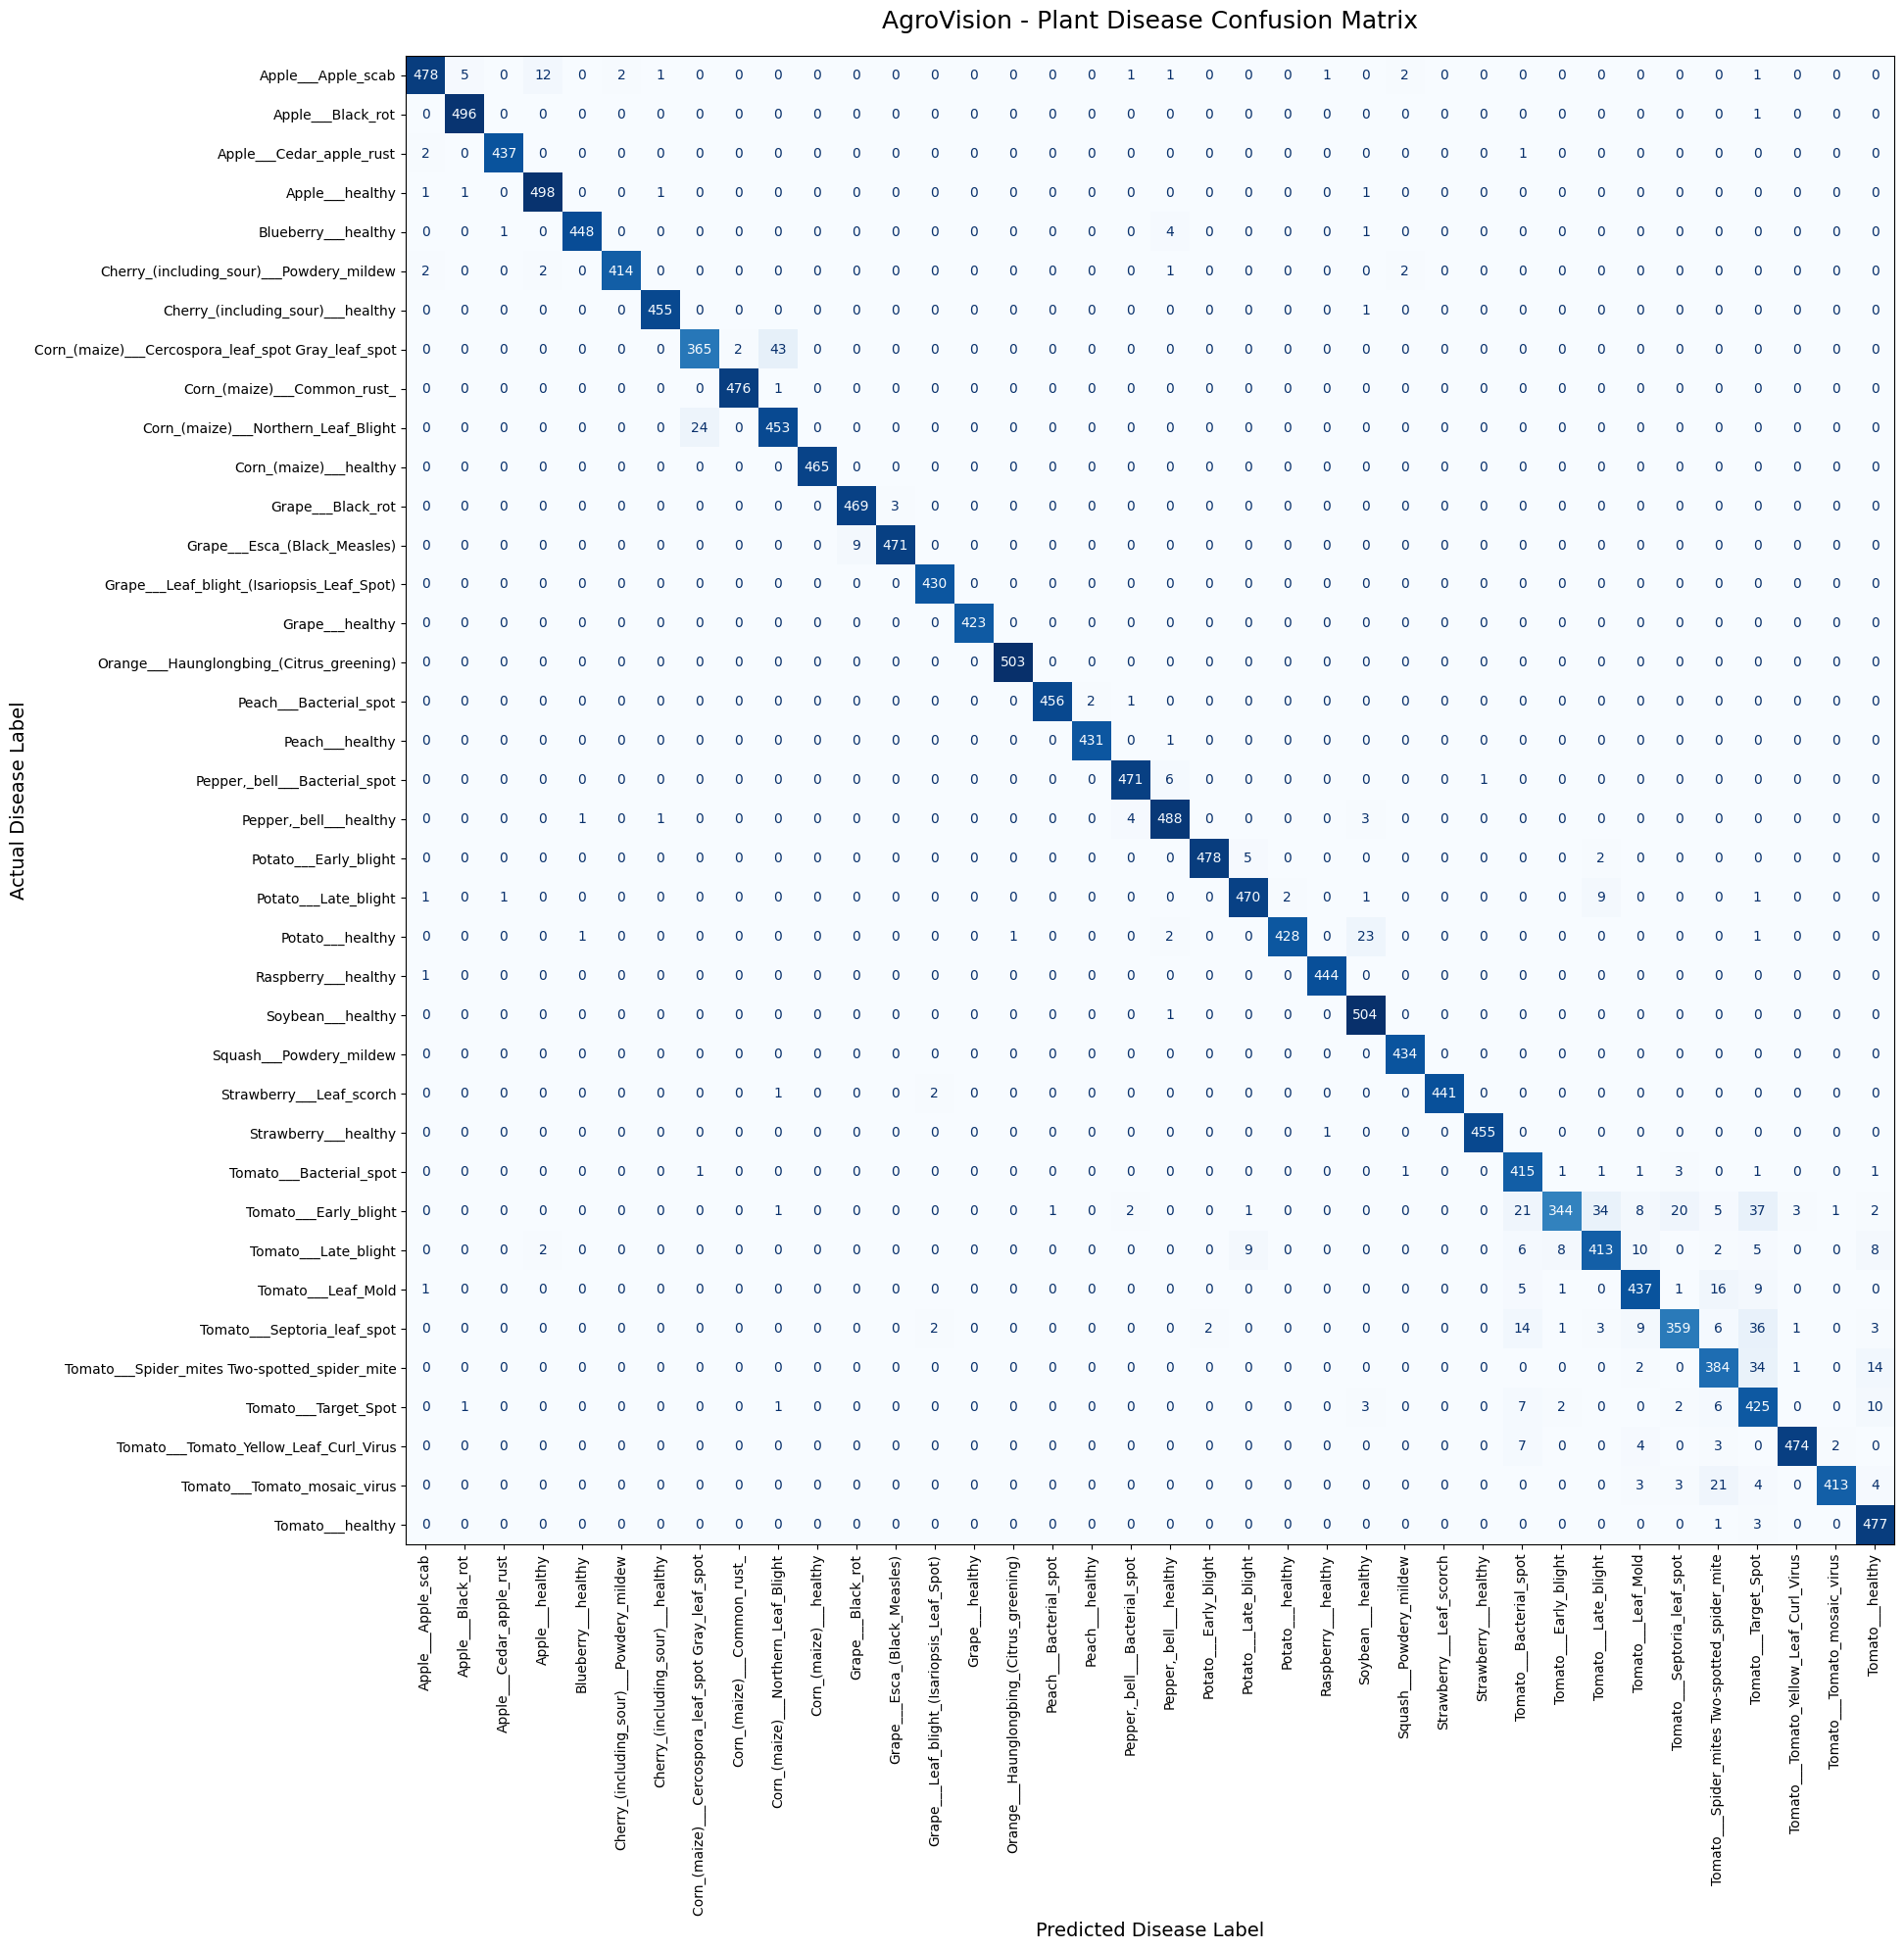

In [ ]:
import os, zipfile, json
from pathlib import Path
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

ZIP_PATH     = "/content/drive/MyDrive/new_plantset.zip"
EXTRACT_PATH = Path("/content/plantvillage")
MODEL_PATH   = "/content/drive/MyDrive/agrovision_model/best_model.keras"
CLASS_PATH   = "/content/drive/MyDrive/agrovision_model/class_names.json"

# 2. Extract dataset if not already extracted
if not EXTRACT_PATH.exists():
    print("Extracting validation images from Drive zip (this takes ~1-2 mins)...")
    with zipfile.ZipFile(ZIP_PATH, 'r') as z:
        z.extractall(EXTRACT_PATH)
    print("✓ Extraction complete!")

# 3. Locate the validation folder automatically
val_dir = None
for p in EXTRACT_PATH.rglob("*"):
    if p.is_dir() and p.name in ("valid", "val", "validation"):
        val_dir = p
        break

if val_dir is None:
    raise FileNotFoundError("Could not find validation folder inside extracted zip.")

print(f"✓ Using validation directory: {val_dir}")

# 4. Load the already-trained model & saved classes
model = tf.keras.models.load_model(MODEL_PATH)
class_names = json.load(open(CLASS_PATH))
print(f"✓ Loaded model with {len(class_names)} classes.")

# 5. Load validation dataset (shuffle=False is required!)
val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=(224, 224),
    batch_size=16,
    shuffle=False
)

# 6. Generate Predictions
print("\nEvaluating model across all validation images...")
y_true = np.concatenate([y.numpy() for x, y in val_ds], axis=0)

y_pred_probs = model.predict(val_ds)
y_pred = np.argmax(y_pred_probs, axis=1)

# 7. Print & Save Classification Report
print("\n" + "=" * 65)
print("📊 CLASSIFICATION REPORT (PRECISION, RECALL, F1-SCORE)")
print("=" * 65)
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
)
print(report)

# Save text report to Drive
report_save_path = "/content/drive/MyDrive/agrovision_model/classification_report.txt"
with open(report_save_path, "w") as f:
    f.write(report)
print(f"✓ Saved Classification Report: {report_save_path}")

# 8. Generate & Save Confusion Matrix
print("\nPlotting Confusion Matrix Heatmap...")
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(20, 20))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
disp.plot(
    ax=ax,
    xticks_rotation="vertical",
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("AgroVision - Plant Disease Confusion Matrix", fontsize=18, pad=20)
plt.xlabel("Predicted Disease Label", fontsize=14)
plt.ylabel("Actual Disease Label", fontsize=14)
plt.tight_layout()

cm_save_path = "/content/drive/MyDrive/agrovision_model/confusion_matrix.png"
plt.savefig(cm_save_path, dpi=300)
print(f"✓ Saved Confusion Matrix: {cm_save_path}")
plt.show()

In [ ]:
import numpy as np
import json
import tensorflow as tf
from google.colab import drive, files

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Load the saved model AND class names from Google Drive
MODEL_PATH = "/content/drive/MyDrive/agrovision_model/best_model.keras"
CLASS_PATH = "/content/drive/MyDrive/agrovision_model/class_names.json"

print("Loading model from Drive...")
model = tf.keras.models.load_model(MODEL_PATH)
CLASSES = json.load(open(CLASS_PATH))
print(f"✓ Model and {len(CLASSES)} classes loaded successfully!")

# 3. Prediction function
def predict(image_path):
    # Load and resize
    img = tf.keras.utils.load_img(image_path, target_size=(224, 224))
    x   = tf.keras.utils.img_to_array(img)
    x   = np.expand_dims(x, 0)  # Shape: (1, 224, 224, 3)

    # Predict
    probs = model.predict(x, verbose=0)[0]
    top5  = np.argsort(probs)[-5:][::-1]

    print(f"\nTop 5 predictions for {image_path}:")
    for i in top5:
        bar = "█" * int(probs[i] * 40)
        print(f"  {CLASSES[i]:45} {probs[i]*100:6.2f}%  {bar}")

# 4. Upload and test
print("\nUpload a leaf photo:")
uploaded = files.upload()
for name in uploaded.keys():
    predict(name)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loading model from Drive...
✓ Model and 38 classes loaded successfully!

Upload a leaf photo:


Saving WhatsApp Image 2026-10-30 at 2.07.12 PM.jpeg to WhatsApp Image 2026-10-30 at 2.07.12 PM.jpeg

Top 5 predictions for WhatsApp Image 2026-10-30 at 2.07.12 PM.jpeg:
  Apple___Cedar_apple_rust                      100.00%  ███████████████████████████████████████
  Blueberry___healthy                             0.00%  
  Peach___Bacterial_spot                          0.00%  
  Apple___Apple_scab                              0.00%  
  Apple___Black_rot                               0.00%  
